# Segmentação de Imagens Acústicas de Poço sem *Ground Truth* (WAID)

**ELE2346 – Deep Learning** · Mestrado em Engenharia Elétrica (Sistemas Inteligentes) · PUC-Rio · 2026.2
Autor: Jorge Alberto Avelino de Souza

**Notebook 04 – Teste sintético e referência da Fase 3.** Dados: WAID (PETROBRAS, CC BY 4.0), 5 poços.

## Fase 3 – Experimentação
Teste sintético (senoides com máscara exata) e treino de referência com a métrica sintética (IoU e Dice).

### 4.1 Ambiente: bibliotecas, Google Drive e GPU
Importando as bibliotecas, montando o Drive e instalando a biblioteca de segmentação.

In [1]:
# Importando as bibliotecas usadas no notebook
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from google.colab import drive

In [2]:
# Montando o Drive para uso dos arquivos WAID
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
# Instalando a biblioteca com a U-Net e o encoder ResNet18 (o Colab já traz o torch)
!pip install -q segmentation-models-pytorch

### 4.2 Configuração do projeto
Ajustando o caminho de busca, importando as funções de `src` e definindo os parâmetros dos treinos.

In [4]:
# Adicionando ao caminho de busca do Python a pasta que contém "src"
sys.path.insert(0, "/content/drive/MyDrive/waid")

# Importando as constantes e as funções do projeto
from src.config import POCOS, NPY_DIR, CARAC_DIR, ANOT_DIR, RES_DIR, ALTURA_PATCH
from src.data.dataset_patches import preparar_dados
from src.synth.sintetico import gerar_sintetico, resumo_sintetico, prever_otsu
from src.train.treino import CFG_PADRAO, rodar_lowo

# Escolhendo o dispositivo (GPU, se houver)
DISP = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("dispositivo:", DISP, torch.cuda.get_device_name(0) if DISP.type == "cuda" else "")

# Definindo os parâmetros dos treinos
CFG = dict(CFG_PADRAO, epocas=10)
MODELOS = ["cnn_rasa", "unet_resnet18"]
SEMENTES = [0, 1, 2]

dispositivo: cuda Tesla T4


### 4.3 Dados
Carregando imagens, limiares de Otsu, índice de treino e anotações.

In [5]:
# Carregando os dados (imagens na memória, limiar de Otsu por poço, patches sem sobreposição com os anotados)
imagens, limiares, indice_treino, anot = preparar_dados(NPY_DIR, CARAC_DIR, ANOT_DIR, POCOS, ALTURA_PATCH)
print({p: round(v, 3) for p, v in limiares.items()})
print(len(indice_treino), "patches para treino, validação e fundos sintéticos")

{'antilope25': 0.541, 'antilope37': 0.623, 'botorosa47': 0.67, 'coala88': 0.682, 'tatu22': 0.76}
3227 patches para treino, validação e fundos sintéticos


### 4.4 Teste sintético: exemplos
Cada fundo é um trecho real com baixa fração escura. Cada fundo recebe 1 ou 2 senoides (1 volta completa, 4 a 8 linhas de espessura, 10 a 60 linhas de altura) em três contrastes (valor dentro da senoide = 0,25, 0,75 e 0,95 vezes o limiar de Otsu do poço; 0,95 é quase o limiar). A máscara é exata. Pixels que já eram escuros no fundo, fora da senoide, não contam como erro. Os parâmetros são escolhas deste trabalho, sem validação por especialista.

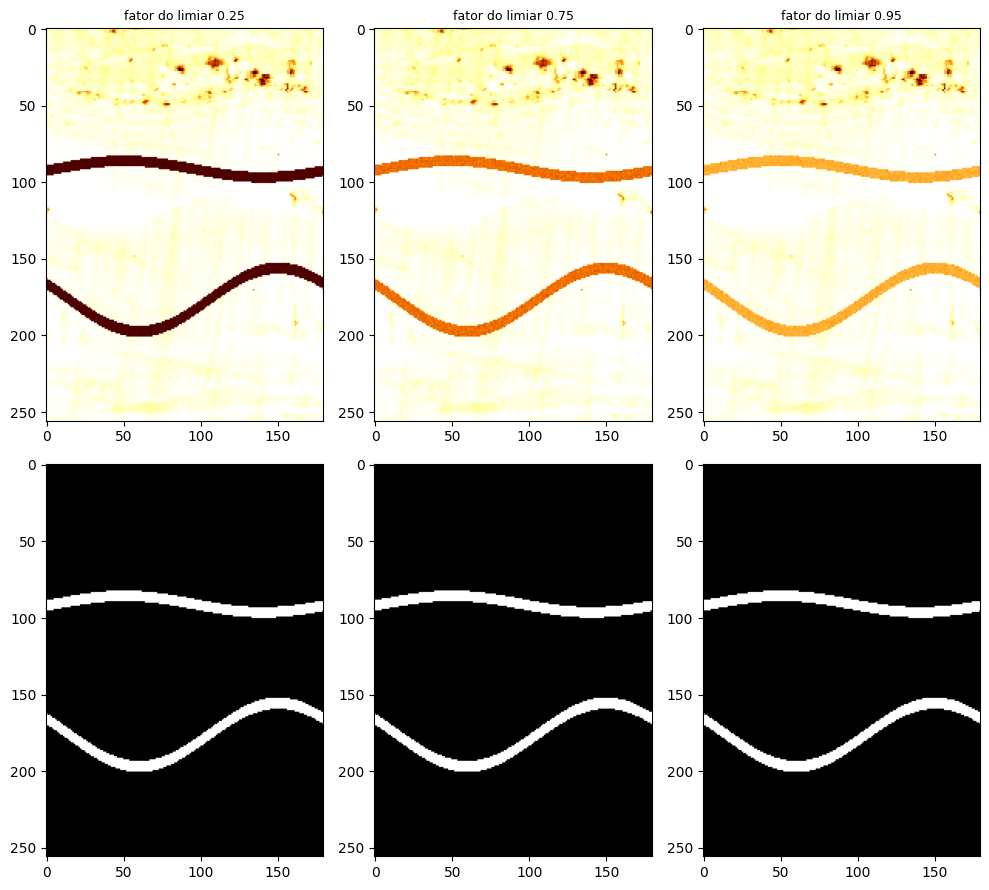

72 patches sintéticos por poço; 3.923% dos pixels pertencem às senoides


In [6]:
# Gerando o conjunto sintético de um poço e mostrando 3 exemplos (imagem, máscara exata)
xs, ms, ig, meta = gerar_sintetico(imagens, indice_treino, limiares["antilope37"], "antilope37")
fig, eixos = plt.subplots(2, 3, figsize=(10, 9))
for j, k in enumerate([0, 1, 2]):
    eixos[0, j].imshow(xs[k], aspect="auto", cmap="afmhot", vmin=0, vmax=1)
    eixos[0, j].set_title(f"fator do limiar {meta.fator[k]}", fontsize=9)
    eixos[1, j].imshow(ms[k], aspect="auto", cmap="gray")
fig.tight_layout()
plt.show()
print(len(xs), "patches sintéticos por poço;", f"{ms.mean():.3%} dos pixels pertencem às senoides")

### 4.5 Baseline de limiar no teste sintético
Aplicando o limiar de Otsu de cada poço aos patches sintéticos. Esse resultado é a referência: os modelos aprendem a imitar esse limiar.

In [7]:
# Calculando IoU e Dice do limiar de Otsu em cada poço, no conjunto sintético
linhas = []
for p in POCOS:
    xs, ms, ig, meta = gerar_sintetico(imagens, indice_treino, limiares[p], p)
    linhas.append({"modelo": "otsu", "poco_teste": p, **resumo_sintetico(prever_otsu(xs, limiares[p]), ms, ig, meta)})
otsu_sint = pd.DataFrame(linhas)
otsu_sint.to_csv(f"{RES_DIR}/sintetico_otsu.csv", index=False)
print(otsu_sint.round(3).to_string(index=False))

modelo poco_teste  iou_sint  dice_sint  iou_sint_25  dice_sint_25  iou_sint_75  dice_sint_75  iou_sint_95  dice_sint_95
  otsu antilope25     0.971      0.985          1.0           1.0          1.0           1.0        0.913         0.955
  otsu antilope37     0.980      0.990          1.0           1.0          1.0           1.0        0.940         0.969
  otsu botorosa47     0.984      0.992          1.0           1.0          1.0           1.0        0.952         0.975
  otsu    coala88     0.985      0.992          1.0           1.0          1.0           1.0        0.955         0.977
  otsu     tatu22     0.990      0.995          1.0           1.0          1.0           1.0        0.971         0.985


### 4.6 Treino de referência com métrica sintética
Repetindo o *leave-one-well-out* da CNN rasa e da U-Net com 3 sementes. O treino é o mesmo do notebook 03; a diferença é que cada *fold* agora também mede IoU e Dice no conjunto sintético do poço de teste. Os resultados vão para `results/modelos_sint/`, sem sobrescrever os do notebook 03. Tempo previsto: cerca de 46 min.

In [8]:
# Rodando o leave-one-well-out de referência (cada fold é salvo; se o Colab cair, executar de novo continua)
escores, resumos = rodar_lowo(MODELOS, SEMENTES, POCOS, imagens, indice_treino, anot, limiares,
                              CFG, DISP, f"{RES_DIR}/modelos_sint")
resumos.to_csv(f"{RES_DIR}/modelos_sint_resumos.csv", index=False)

### 4.7 Resumo: IoU e Dice sintéticos
Média entre poços de teste, depois média e desvio-padrão entre as sementes.

In [9]:
# Calculando a média entre poços por modelo e semente, depois média e desvio entre sementes
colunas = ["dice_pseudo_teste", "iou_sint", "dice_sint", "iou_sint_25", "iou_sint_75", "iou_sint_95"]
por_semente = resumos.groupby(["modelo", "semente"])[colunas].mean()
print(por_semente.round(3))
print()
print(por_semente.groupby("modelo").agg(["mean", "std"]).round(3).T)

# Mostrando o limiar de Otsu para comparação (média entre poços)
print()
print(otsu_sint[["iou_sint", "dice_sint", "iou_sint_25", "iou_sint_75", "iou_sint_95"]].mean().round(3))

                       dice_pseudo_teste  iou_sint  dice_sint  iou_sint_25  \
modelo        semente                                                        
cnn_rasa      0                    0.664     0.770      0.819        0.918   
              1                    0.667     0.754      0.809        0.919   
              2                    0.708     0.795      0.849        0.896   
unet_resnet18 0                    0.626     0.761      0.822        0.875   
              1                    0.636     0.796      0.847        0.930   
              2                    0.613     0.757      0.802        0.921   

                       iou_sint_75  iou_sint_95  
modelo        semente                            
cnn_rasa      0              0.925        0.465  
              1              0.872        0.471  
              2              0.917        0.574  
unet_resnet18 0              0.851        0.558  
              1              0.909        0.548  
              2          